### 검색 Tool이 필요한 이유
- LLM의 파라미터에 담긴 지식은 최신 사실을 보장하지 않음
- 웹 검색 도구는 외부 자료를 가져오는 역할
- 검색 결과 자체가 틀리거나 악성 지시를 포함할 수 있으므로 신뢰할 수 있는 출처와 날짜를 확인

```
사용자 -> LLM -> 검색 필요? -> 아니오 -> 답변
                          -> 예 -> 검색 Tool -> 결과 확인 -> LLM -> 답변
```

# **1 Tavily**
AI 애플리케이션과 Agent가 웹에서 정보를 검색하고, 검색 결과의 제목/주소/본문 일부를 구조화된 데이터로 받도록 지원하는 검색 API 서비스

In [1]:
import os
from dotenv import load_dotenv

In [2]:
load_dotenv()
OPENAI_API_KEY = bool(os.getenv("OPENAI_API_KEY"))
TAVILY_API_KEY = bool(os.getenv("TAVILY_API_KEY"))
OPENAI_MODEL = bool(os.getenv("OPENAI_MODEL"))
print("OPENAI_API_KEY:", OPENAI_API_KEY, "| TAVILY_API_KEY:", TAVILY_API_KEY, "| OPENAI_MODEL:", OPENAI_MODEL)

OPENAI_API_KEY: True | TAVILY_API_KEY: True | OPENAI_MODEL: True


In [3]:
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-6-luna")

In [4]:
from langchain_openai import ChatOpenAI

In [5]:
def make_llm():
    if not OPENAI_API_KEY:
        print("KEY ERROR")
        return None
    return ChatOpenAI(model=MODEL_NAME, reasoning_effort="none", timeout=30, max_retries=2, temperature=0)

In [6]:
llm = make_llm()

In [7]:
from tavily import TavilyClient   # pip install tavily

In [8]:
if TAVILY_API_KEY:
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    raw_search = tavily_client.search(query="랭그래프는 뭐야?", max_results=3)
    print("최상위 키:", list(raw_search.keys()))
    for idx, item in enumerate(raw_search.get("results", []), start=1):
        print(f"\n[{idx}] 제목:", item.get("title", ""))
        print("주소:", item.get("url", ""))
        print("요약:", str(item.get("content", ""))[:200])
else:
    print("KEY ERROR")

최상위 키: ['query', 'follow_up_questions', 'answer', 'images', 'results', 'response_time', 'request_id']

[1] 제목: LangGraph란 무엇이고 언제 쓰면 좋을까?
주소: https://velog.io/@ohback/LangGraph
요약: 여기서 등장하는 게 LangGraph다. 이름 그대로 그래프(노드/엣지)로 LLM 애플리케이션의 흐름을 설계한다.  
 LangChain이 블록(모델·프롬프트·툴)을 잘 조립하게 해주는 공구상자라면, LangGraph는 그 블록들이 언제, 어떤 조건으로, 어떤 상태를 들고 움직일지를 정밀하게 오케스트레이션하는 조감도 + 신호등에 가깝다.

  

## 그래

[2] 제목: 꿈 많은 사람의 이야기
주소: https://lsjsj92.tistory.com/696
요약: ## LangGraph란?

LangGraph는 LLM을 기반으로 상태를 유지하고(Stateful), 여러 단계에 걸쳐 작동하는(multi-step) 에이전트를 구축하기 위한 라이브러리입니다. 기존의 LangChain이 LLM과 외부 도구를 '연쇄적으로(chaining)' 연결하는 데 중점을 두었다면, LangGraph는 이러한 연결 구조를 순환(cycle

[3] 제목: 23화 22. LangGraph 기본과 응용
주소: https://brunch.co.kr/@aideveloper/132
요약: # 22. LangGraph 기본과 응용

LLM 시대, LangChain(랭체인)으로 배우는 AI 소프트웨어 개발

gaebalai-blog_ai-v3-1.jpg

## (1) LangGraph(랭그래프)란?

LangGraph(랭그래프)는 LangChain(랭체인)을 기반으로 하는 에이전트 프레임워크입니다. LangGraph(랭그래프)의 주요 특징은 복


In [9]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch

In [10]:
if llm is not None and TAVILY_API_KEY:
    search_tool = TavilySearch(max_results=3)
    search_llm = llm.bind_tools([search_tool])

    def search_agent_node(state: MessagesState):
        response = search_llm.invoke(state["messages"])
        return {"messages": [response]}

    search_builder = StateGraph(MessagesState)
    search_builder.add_node("agent", search_agent_node)
    search_builder.add_node("tools", ToolNode([search_tool]))
    search_builder.add_edge(START, "agent")
    search_builder.add_conditional_edges("agent", tools_condition)
    search_builder.add_edge("tools", "agent")
    search_graph = search_builder.compile()
    result = search_graph.invoke(
        {"messages": [{"role": "user", "content": "LangGraph 최신 공식 문서를 찾아줘"}]},
        config = {"recursion_limit": 10}
    )
    for message in result["messages"]:
        print(type(message).__name__, str(message.content)[:500])
else:
    print("KEY ERROR")

HumanMessage LangGraph 최신 공식 문서를 찾아줘
AIMessage 
ToolMessage {"query": "LangGraph official documentation latest", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://docs.langchain.com/oss/python/langgraph/overview", "title": "LangGraph overview - Docs by LangChain", "content": "Trusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. LangGraph gives you
AIMessage LangGraph 최신 공식 문서는 아래에서 확인할 수 있습니다.

- **LangGraph 공식 문서 — Python**
  https://docs.langchain.com/oss/python/langgraph/overview
- **LangGraph 공식 문서 — JavaScript/TypeScript**
  https://docs.langchain.com/oss/javascript/langgraph/overview
- **LangChain 공식 문서 홈**
  https://docs.langchain.com/
- **공식 릴리스 변경 사항(Changelog)**
  https://docs.langchain.com/oss/python/releases/changelog

문서에서 다루는 주요 내용은 다음과 같습니다.

- 그래프 및 상태(State) 설계


# **2. Reflection vs Reflexion**
- Reflection(반성)은 작성한 초안을 스스로 검토하고 고치는 작업
- Reflexion(확장형 반성)은 여러 번의 시도에서 실패 원인과 피드백을 기억해 다음 시도 전략까지 바꾸는 접근

> 공통점은 둘 다 "자기 평가"가 항상 맞다는 뜻은 아님

- 구성 요소: 초안 생성 > 평가 > 피드백 > 수정 > 재평가
- 평가 기준: 사실 정확성, 근거, 형식, 독자 수준, 빠진 항목
- 종료 조건: 통과 기준 만족, 최대 시도 횟수, 비용 상한
- 흔한 오류: LLM이 점수만 매기고 수정 지시를 전달하지 않은 것

In [11]:
from typing import TypedDict, Literal

In [12]:
class ReviewState(TypedDict):
    topic: str       # 주제
    draft: str       # 초안
    feedback: str    # 검토 결과, 수정 의견
    approved: bool   # 초안의 통과 여부
    attempts: int    # 작성한 횟수

# 초안 작성 또는 수정
def write_draft(state: ReviewState):
    text = f"{state["topic"]}은 중요한 개념입니다."
    if state["attempts"] > 0:
        text += "예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다."
    return {"draft": text, "attempts": state["attempts"] + 1}

# 초안의 통과 여부 판단
def review_draft(state: ReviewState):
    good = "예시:" in state["draft"]
    return {"approved": good, "feedback": "통과" if good else "구체적인 예시를 추가하세요"}

# 조건 함수: 다시 작성할지 종료할지 결정
def review_route(state: ReviewState) -> Literal["write", "finish"]:
    return "finish" if state["approved"] or state["attempts"] >= 3 else "write"


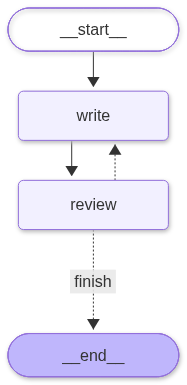

In [13]:
review_builder = StateGraph(ReviewState)
review_builder.add_node("write", write_draft)
review_builder.add_node("review", review_draft)
review_builder.add_edge(START, "write")
review_builder.add_edge("write", "review")
review_builder.add_conditional_edges("review", review_route, {"write": "write", "finish": END})
review_graph = review_builder.compile()
review_graph


In [14]:
review_result = review_graph.invoke({"topic": "RAG", "draft": "", "feedback": "", "approved": False, "attempts": 0})
print(review_result)

{'topic': 'RAG', 'draft': 'RAG은 중요한 개념입니다.예시: 사용자의 질문을 검색하고 근거를 붙여 답합니다.', 'feedback': '통과', 'approved': True, 'attempts': 2}


In [15]:
from pydantic import BaseModel, Field

In [16]:
class DraftGrade(BaseModel):
    score: int = Field(ge=0, le=5, description="정확성/구체성 기준 0~5점")
    strengths: str = Field(description="잘된 점")
    weaknesses: str = Field(description="부족한 점")
    revision_instrunction: str = Field(description="다음 수정 지시")

In [17]:
if llm is not None:
    grader = llm.with_structured_output(DraftGrade)
    sample_draft = "RAG는 문서를 찾아 답변을 만드는 방법입니다."
    grade = grader.invoke("다음 설명을 초보자용 교재 기분으로 평가하세요. 정확성, 예시, 주의사항을 확인하세요.\n" + sample_draft)
    print(grade.model_dump())

else:
    print("KEY ERROR")

{'score': 2, 'strengths': 'RAG를 문서 검색과 답변 생성의 결합으로 간단히 설명해 초보자가 핵심 개념에 접근하기 쉽습니다.', 'weaknesses': '‘문서를 찾아 답변을 만드는 방법’이라는 설명은 지나치게 단순합니다. RAG는 일반적으로 사용자의 질문과 관련된 외부 문서나 지식베이스를 검색(Retrieval)한 뒤, 검색 결과를 생성형 언어 모델의 입력 맥락으로 제공하여 답변을 생성(Augmented Generation)하는 구조입니다. 검색과 생성이 각각 어떤 역할을 하는지, 왜 사용하는지(최신 정보 반영, 특정 문서 기반 답변, 환각 감소 등)가 빠져 있습니다. 예시가 없고, 검색된 문서가 부정확하거나 부족하면 답변도 틀릴 수 있다는 주의사항도 제시되지 않았습니다.', 'revision_instrunction': '다음처럼 보완하세요: ‘RAG(Retrieval-Augmented Generation)는 사용자의 질문과 관련된 문서를 먼저 검색한 뒤, 검색된 내용을 참고하도록 언어 모델에 제공하여 답변을 생성하는 방법입니다. 예를 들어 사내 규정에 대해 질문하면, RAG는 관련 규정 문서를 찾아 그 내용을 바탕으로 답변합니다. 따라서 최신 문서나 특정 자료를 활용할 수 있지만, 검색 결과가 부정확하거나 관련 문서가 없으면 답변도 부정확할 수 있습니다.’'}


In [18]:
if llm is not None:
    original = "RAG는 검색을 합니다"
    feedback = "정의와 실제 예시, 한계점을 추가하세요"
    improved = llm.invoke(
        "당신은 AI 교육 교재 편집자입니다. 사실을 지어내지 마세요. \n"
        f"원문: {original}\n피드백: {feedback}\n 수정본만 작성하세요."
    )
    print(improved.content)

RAG(Retrieval-Augmented Generation)는 외부 문서나 데이터베이스에서 관련 정보를 검색한 뒤, 검색 결과를 바탕으로 답변을 생성하는 방식입니다. 예를 들어 사내 규정 문서에서 휴가 관련 내용을 검색하고, 그 결과를 근거로 직원의 질문에 답할 수 있습니다. 다만 검색된 정보가 부정확하거나 최신이 아니면 답변도 잘못될 수 있으며, 관련 문서를 찾지 못하거나 검색 결과의 품질이 낮을 때 성능이 제한됩니다.


# **3. RAG**
RAG(Retrieval_Augmunted Generation)는 생성형 AI가 외부 지식을 검색해 활용하는 방식으로,  
단순히 모델 파라미터에 저장된 정보만으로 답변하지 않고, 관련 문서를 검색(Retrieval)한 뒤 이를 입력 맥락에 포함시켜 답변을 생성합니다.  
이 방식은 모델이 최신 정보나 도메인 특화 지식을 활용할 수 있게 해주며, 환각(hallucination)을 줄이고 신뢰도를 높입니다.  
예를 들어 고객 지원, 법률 문서 검색, 논문 요약 등에서는 내부 데이터베이스에서 필요한 정보를 불러온 후 답변을 생성하는 형태로 적용됩니다.

### RAG 워크플로우
- 질문을 입력받은 뒤 쿼리를 벡터로 변환해 벡터DB에서 관련 문서를 검색하고 이를 컨텍스트로 합쳐 LLM이 답변을 생성하는 단일 경로의 직선형 파이프라인
- 검색과 생성이 고정된 순서로 연결되어 있어 빠르고 단순하며, FAQ나 사내 문서 QA처럼 명확한 질문/답변 작업에 적합

### 에이전틱 RAG 워크플로우
- 기본 RAG흐름 위에 에이전트의 자율성을 추가해 질문을 분석하고 필요할 때만 검색하거나 쿼리를 재작성해 여러 번 검색하며 검색 결과를 평가/반성 후 재시도하는 다단계 반복형 파이프라인입니다.  
LLM이 언제 검색할지, 어떤 도구를 쓸지, 어떻게 답변을 다듬을지까지 스스로 결정하므로 복잡한 리서치, 멀티홉 질의, 장기 과제에 더 강력합니다.
    - 단일 홉(Single-hop): 하나의 문서/사실만 찾아도 바로 답 가능

### RAG의 역할
- 검색(Retrieval): 질문과 관련된 자료를 찾음
- 증강(Augmentation): 검색 자료를 프롬프트의 근거로 제공
- 생성(Generation): 근거를 읽고 답변 작성

> RAG가 환각을 자동으로 없애지는 않음. 검색 실패, 오래된 문서, 잘못된 근거 연결, LLM의 근거 오독이 남음

In [19]:
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader

C:\Users\SHJ\AppData\Local\Temp\ipykernel_19688\1909073654.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [20]:
pdf_candidates = sorted(Path.cwd().glob("SPRi*.pdf"))
print("현재 폴더:", Path.cwd())
print("발견한 PDF:", [p.name for p in pdf_candidates])

현재 폴더: c:\SHJ\KDT\14_Agent
발견한 PDF: ['SPRi AI Brief 2026년 10월호(2026-10-09).pdf']


In [21]:
pdf_path = pdf_candidates[0]
pdf_pages = PyPDFLoader(str(pdf_path)).load()
print("읽은 PDF 페이지 수:", len(pdf_pages))
print("첫 페이지의 메타데이터:", pdf_pages[0].metadata)
print("PDF 5페이지 일부:", pdf_pages[4].page_content[:500])

Ignoring wrong pointing object 7 0 (offset 0)
Ignoring wrong pointing object 18 0 (offset 0)
Ignoring wrong pointing object 25 0 (offset 0)
Ignoring wrong pointing object 30 0 (offset 0)
Ignoring wrong pointing object 38 0 (offset 0)
Ignoring wrong pointing object 49 0 (offset 0)
Ignoring wrong pointing object 57 0 (offset 0)
Ignoring wrong pointing object 64 0 (offset 0)
Ignoring wrong pointing object 72 0 (offset 0)
Ignoring wrong pointing object 80 0 (offset 0)
Ignoring wrong pointing object 90 0 (offset 0)
Ignoring wrong pointing object 98 0 (offset 0)
Ignoring wrong pointing object 106 0 (offset 0)
Ignoring wrong pointing object 113 0 (offset 0)
Ignoring wrong pointing object 120 0 (offset 0)
Ignoring wrong pointing object 131 0 (offset 0)
Ignoring wrong pointing object 139 0 (offset 0)
Ignoring wrong pointing object 146 0 (offset 0)
Ignoring wrong pointing object 153 0 (offset 0)
Ignoring wrong pointing object 160 0 (offset 0)
Ignoring wrong pointing object 170 0 (offset 0)
Ignor

읽은 PDF 페이지 수: 28
첫 페이지의 메타데이터: {'producer': 'macOS 버전 26.6.2(빌드 25G83) Quartz PDFContext', 'creator': '한글', 'creationdate': "D:20261009073006Z00'00'", 'moddate': "D:20261009073006Z00'00'", 'title': '무제', 'source': 'c:\\SHJ\\KDT\\14_Agent\\SPRi AI Brief 2026년 10월호(2026-10-09).pdf', 'total_pages': 28, 'page': 0, 'page_label': '1'}
PDF 5페이지 일부: SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
4
EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도
328)287
EU 「AI 법」의 투명성 의무가 2026년 8월 2일 적용 개시되었고, EU 집행위원회는 범용 AI 모델 
의무 준수 여부를 확인하기 위해 전 세계 30여 개 범용 AI 모델 제공 기업에 정보 요청 전달 
미국은 G20 혁신 장관회의에서 특정 기술만을 겨냥한 신규 규제를 지양하는 '캐롤라이나 원칙'을 제
시하였고, G20 회원국은 합의한 장관 성명에서 이 원칙을 참고해 각국 정책 체계를 수립하기로 함
EU, 투명성 의무 적용 개시하고, 범용 AI 모델 의무 집행 개시
유럽연합(EU)의 포괄적 AI 규제 법인 「AI 법」의 투명성 의무가 2026년 8월 2일부터 적용 개시
이에 따라 AI 시스템 제공자와 배포자는 사용자가 AI와 상호작용하고 있음을 고지하고, AI 생성 콘텐츠에 
기계 판독 가능한 표시를 제공하며, 딥페이크 등


- Chunk(청크): 긴 문서를 검색하기 쉬운 작은 조각으로 분할한 것. 너무 작으면 맥락이 끊기고 너무 크면 잡음이 늘어남
- Vector DB(벡터 DB): 임베딩을 저장하고 유사한 벡터를 검색하는 시스템.
- Retriever(검색기): 질문을 받아 관련 문서 목록을 반환하는 인터페이스
- Overlap(겹침): 문장 경계에서 정보가 끊기는 현상을 줄임. 저장량과 중복 결과를 늘림

In [22]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [23]:
# RecursiveCharacterTextSplitter: 문단, 줄바꿈, 공백 등을 우선 고려해 분할하는 도구
pdf_splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100)
pdf_chunks = pdf_splitter.split_documents(pdf_pages)
for i, doc in enumerate(pdf_chunks):
    doc.metadata["doc_id"] = f'SPRi-{i:04d}'
    doc.metadata["page_display"] = int(doc.metadata.get("page", 0)) + 1
print("페이지:", len(pdf_pages), "청크:", len(pdf_chunks))

페이지: 28 청크: 86


In [24]:
for doc in pdf_chunks[:2]:
    print("ID:", doc.metadata["doc_id"], "PDF 쪽:", doc.metadata["page_display"])
    print(repr(doc.page_content[:200]))

ID: SPRi-0000 PDF 쪽: 1
'10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'
ID: SPRi-0001 PDF 쪽: 2
'Ἂк\x0b\x13ዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2\n⁋⑻\n･\nᓋ⁒\n∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4\n∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5\n∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6\n∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7\n∙중국 최고인민법원, A'


### metadata를 보존하는 이유
- 검색 결과가 예를 들어 "EU AI 법의 투명성 의무"라고 말할 때 어느 페이지에서 나온 말인지 알아야 함
- doc_id는 검색 결과를 중복 제거하거나 평가할 때 사용하는 청크 ID
- page_display는 PDF 뷰어에서 볼 수 있는 1부터 시작하는 페이지 번호
    - 보고서 본문에 인쇄된 쪽수와 PDF 뷰어 쪽수는 표지/목차 때문에 다를 수 있음

- Vector Store: 데이터를 저장/검색하는 시스템
- BM25Retriever: 단어 기반 검색기
- Query: 검색할 질문/검색어
- Corpus: 검색 대상 문서 전체
- Candidate: 검색기가 찾아낸 문서

In [25]:
import re
from langchain_community.retrievers import BM25Retriever

In [26]:
def simple_tokens(text: str):
    return re.findall(r"[가-힣A-Za-z0-9]+", text.lower())

pdf_bm25 = BM25Retriever.from_documents(pdf_chunks, preprocess_func=simple_tokens)
pdf_bm25.k = 4    # 가져올 결과 개수토
pdf_hits = pdf_bm25.invoke("Muse 개인용 AI 에이전트 기능")
for rank, doc in enumerate(pdf_hits, start=1):
    print(f"{rank}위 | PDF {doc.metadata['page_display']}쪽 | {doc.metadata['doc_id']}")
    print(doc.page_content[:200].replace("\n", " "))

1위 | PDF 13쪽 | SPRi-0038
328)287 메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 다양한  업무를 수행하는 개인용 AI 에이전트 ‘Muse’ 출시 Muse는 출시 후 첫 12일간 미국·캐나다 iOS 다운로드 수가 ChatGPT
2위 | PDF 2쪽 | SPRi-0001
Ἂкዞம⸺⺟ ∙ 2026년 9월 AI 모델 현황 2 ⁋⑻ ･ ᓋ⁒ ∙ EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 4 ∙미·중 정상, ‘초지능’ 대화와 소통 창구 구축 합의 5 ∙미국 의회, 잇단 AI 규제 발의에도 입법은 정체 6 ∙미국 사이버보안 합동 권고문, 대규모 지식 증류를 통한 모델 탈취 경고 7 ∙중국 최고인민법원, A
3위 | PDF 13쪽 | SPRi-0040
앱토피아(Apptopia)에 따르면 Muse는 출시 첫 12일간 미국·캐나다 iOS에서 180만 건이 다운로드 되어 ChatGPT(130만 건)를 앞섰으며, 같은 기간 전 세계 누적 설치 수는 280만 건을 기록 미국 매체 악시오스(Axios)에 따르면 최근 스타트업과 빅테크가 잇달아 개인용 에이전트 서비스를  출시하며 관련 시장이 활성화 비공개 베타
4위 | PDF 14쪽 | SPRi-0042
328)287 중국 스마트폰 제조사 오포와 비보, 아너가 각각 AI 에이전트에 앱과 개인정보, 기기 기능  접근 권한을 부여하는 신규 운영체제를 공개 3개 스마트폰 제조사가 발표한 신규


In [27]:
# OpenAIEmbeddings: 임베딩 모델. 글자를 의미 비교에 쓸 숫자 배열로 바꿈. PDF 청크 전체를 임베딩하면 API 호출 비용이 많이 발생할 수 있음
# Chroma: 임베딩 벡터와 문서 정보를 저장하고 비슷한 벡터를 검색하는 데이터베이스

from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

In [28]:
if OPENAI_API_KEY:
    pdf_embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
    pdf_vectorsotre = Chroma.from_documents(documents=pdf_chunks, embedding=pdf_embedding_model, collection_name="spri_ai_bref_202610")

    # as_retriever(): 벡터 저장소를 retriever 방식으로 사용할 수 있게 바꿈
    pdf_vector_retriever = pdf_vectorsotre.as_retriever(search_kwargs = {"k": 4})
    pdf_vector_hits = pdf_vector_retriever.invoke("개인 비서가 이메일과 일정 관리를 돕는다는 내용")
    for doc in pdf_vector_hits:
        print(f"PDF {doc.metadata["page_display"]}쪽 | {doc.page_content[:120]}")
else:
    print("KEY ERROR")

PDF 14쪽 | 트에 앱과 개인정보, 기기 기능 접근 권한을 부여하며 AI를 운영체제에 심층 통합하는 단계에 진입
AI 모델이 복잡한 작업을 계획하고 조율하며 완수하도록 돕는 소프트웨어 계층인 ‘하네스(Harness)’를 
핵심 
PDF 13쪽 | SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
12
메타, 개인용 AI 에이전트 ‘Muse’ 출시
328)287
메타가 이메일이나 캘린더, 결제 등 일상적으로 사용하는 앱과 서비스를 연동해 
PDF 13쪽 | 앱토피아(Apptopia)에 따르면 Muse는 출시 첫 12일간 미국·캐나다 iOS에서 180만 건이 다운로드
되어 ChatGPT(130만 건)를 앞섰으며, 같은 기간 전 세계 누적 설치 수는 280만 건을 기록

PDF 8쪽 | 구독 대비 사용량 비율, 신규 계정의 실시간 최대 사용량, 기업 규모의 처리량 패턴도 모니터링 필요
두 번째는 맞춤형 대응 변경 사항 배포로, 악의적 증류 시도가 의심되면 응답 방식을 변경해 증류 활동 제한
세 


### BM25와 벡터 Retriever를 비교
- BM25는 단어가 정확히 들어간 문서를 찾는 데 강함
- 벡터 검색은 다른 표현을 써도 관련 문서를 찾을 가능성이 높음
- 둘 다 틀린 문서를 가져올 수 있으므로 검색 결과를 직접 검토해야 함
- 검색된 4개 문서가 모두 답변에 필요한 근거인 것은 아님. Top-K는 개수 제한이지 정답 보장이 아님

# **4. ChromaDB**
- ChromaDB는 텍스트의 의미를 표현하는 숫자 벡터와 함께 보관하고, 질문 벡터와 가까운 문서를 검색하는 오픈소스 벡터 데이터베이스
- 일반 RDBMS에서 WHERE ... 처럼 정확한 조건을 찾는다면, 벡터 DB는 표현이 달라도 의미가 비슷한 글을 찾는 데 초점을 둠

> 예: gpt-6-luna는 답변을 만드는 자연어 모델이고, text-embedding-3-small은 검색용 숫자를 만드는 별도의 모델. Chroma가 PDF를 직접 이해하거나 답변을 쓰는 것은 아님

[Chroma 공식 문서](https://docs.trychroma.com/docs/overview/introduction) | [LangChain Chroma 연동](https://docs.langchain.com/oss/python/integrations/vectorstores/chroma) | [LangChain Retriever 개념](https://docs.langchain.com/oss/python/integrations/retrievers)

In [29]:
from langchain_core.documents import Document

In [30]:
if OPENAI_API_KEY:
    demo_docs = [
        Document(page_content="메타의 개인용 AI 에이전트는 일정 관리 업무를 돕습니다.", metadata={"source":"demo", "topic":"agent"}),
        Document(page_content="EU AI 법은 인공지능의 투명성과 책임을 다룹니다.", metadata={"source":"demo", "topic":"policy"}),
        Document(page_content="벡터 검색은 의미가 유사한 문서를 찾는 방식입니다.", metadata={"source":"demo", "topic":"search"}),
    ]
    demo_embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
    demo_db = Chroma.from_documents(documents=demo_docs, embedding=demo_embeddings, ids=["demo-1", "demo-2", "demo-3"], collection_name="chroma_intro_class")
    print("문서 수:", demo_db._collection.count())
    for doc in demo_db.similarity_search("개일 비서가 스케줄을 관리하는 기능", k=2):
        print(doc.page_content, doc.metadata)
else:
    print("KEY ERROR")

문서 수: 3
메타의 개인용 AI 에이전트는 일정 관리 업무를 돕습니다. {'topic': 'agent', 'source': 'demo'}
EU AI 법은 인공지능의 투명성과 책임을 다룹니다. {'source': 'demo', 'topic': 'policy'}


In [ ]:
if OPENAI_API_KEY:
    policy_docs = demo_db.similarity_search("AI 규제", k=2, filter={"topic":"policy"})
    print("필터 결과:", [(d.page_content, d.metadata) for d in policy_docs])

    demo_db.add_documents([Document(page_content="사내 FAQ는 인사 정책을 설명합니다.", metadata={"source":"demo", "topic":"hr"})], ids=["demo-4"])
    demo_db.update_documents(ids=["demo-4"], documents=[Document(page_content="사내 FAQ는 연차와 휴가 정책을 설명합니다.", metadata={"source":"demo", "topic":"hr"})])
    print("수정 후:", [d.page_content for d in demo_db.similarity_search("연차", k=1)])

    demo_db.delete(ids=["demo-4"])
    print("삭제 후 문서 수:", demo_db._collection.count())

필터 결과: [('EU AI 법은 인공지능의 투명성과 책임을 다룹니다.', {'topic': 'policy', 'source': 'demo'})]
수정 후: ['사내 FAQ는 연차와 휴가 정책을 설명합니다.']
삭제 후 문서 수: 3


### 저장 폴더 재사용
- persist_directory를 지정하면 Chroma가 로컬 폴더에 데이터를 저장
- 인덱싱(최초 저장)과 검색(재사용) 코드를 분리해야 API 비용과 중복을 줄일 수 있음

In [35]:
if OPENAI_API_KEY:
    persist_path = "./chroma_spri_class_v1"
    embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
    saved_db = Chroma(
        collection_name="spri_pdf_chunks_v1",
        embedding_function=embedding_model,
        persist_directory=persist_path
    )
    if saved_db._collection.count() == 0:
        saved_db.add_documents(pdf_chunks, ids=[d.metadata["doc_id"] for d in pdf_chunks])
        print("최초 색인 완료")
    else:
        print("기존 Chroma 데이터 재사용")
    print("저장 문서 수:", saved_db._collection.count())
    for d in saved_db.similarity_search("EU AI 법 투명성", k=2):
        print("PDF 쪽:", d.metadata.get("page_display"), d.page_content[:120])

최초 색인 완료
저장 문서 수: 86
PDF 쪽: 5 SPRi AI Brief
 2
0
2
6
년
  1
0
월
호
4
EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도
328)287
EU 「AI 법」의 투명성 의무가 2026년 8월 2일 적용
PDF 쪽: 9 이번 지침은 인격권, 개인정보 권익, 소비자 권익 침해 등 AI 관련 침해의 법적 책임을 사업
자, 생성형 AI 서비스 제공자, 사용자 등 주체별로 명확히 규정
합리적 이유 없이 동일 상품이나 서비스에 대하여 서


### 검색 전략 비교
- Similarity: 질문과 가장 가까운 문서부터 가져옴. 같은 내용을 반복해서 가져올 수 있음
- MMR(Maximal Marginal Relevance, 최대 한계 관련성): 질문 관련성과 결과 다양성을 함께 고려. 서로 거의 같은 청크가 여러 개 나오는 문제를 완화
- fetch_k: 후보 수. k는 최종 반환 개수
- Score: 검색 점수를 함께 확인할 수 있음. Chroma/langChain 매서드마다 거리 또는 관련성 점수의 의미가 다르므로 높을수록 좋은지, 낮을수록 좋은지 확인하고 서로 다른 방식의 숫자를 무작정 비교하지 않음
- Filter: 메타데이터 조건으로 검색 범위를 제한. 문서 버전/부서/접근권한 필터링에 사용. 단, DB필터만으로 권한 보안을 완성했다고 생각하면 안됨

In [ ]:
if OPENAI_API_KEY:
    q = "개인용 AI 에이전트와 정책 관련 내용"
    # as_retriever: Chroma 벡터 저장소를 LangChain의 Retriever 인터페이스로 사용하는 메서드
    for label, retriever in {
        # similarity: 유사도 기반, {"k":3}: 검색 결과를 3개 반환
        "similarity": saved_db.as_retriever(search_type="similarity", search_kwargs={"k":3}),
        # k: 최종적으로 반환할 문서 개수
        # fetch_k: 후보로 가져올 문서 개수
        # lambda_mult: 관련성과 다양성의 균형을 조절하는 값. 값을 낮추면 다양성이 높아짐
        "mmr": saved_db.as_retriever(search_type="mmr", search_kwargs={"k":3, "fetch_k":10, "lambda_mult":0.5})
    }.items():
        print("\n[", label, "]")
        for d in retriever.invoke(q):
            print(d.metadata.get("doc_id"), "PDF", d.metadata.get("page_display"), "쪽")
    print("\n[거리 점수: 반환 API의 의미를 확인하세요]")
    # similarity_search_with_score: 반환하는 거리 점수. 일반적으로 낮을수록 가까운 문서 
    for d, score in saved_db.similarity_search_with_score(q, k=3):
        print(d.metadata.get("doc_id"), score)


[ similarity ]
SPRi-0027 PDF 9 쪽
SPRi-0026 PDF 9 쪽
SPRi-0001 PDF 2 쪽

[ mmr ]
SPRi-0027 PDF 9 쪽
SPRi-0009 PDF 5 쪽
SPRi-0049 PDF 17 쪽

[거리 점수: 반환 API의 의미를 확인하세요]
SPRi-0027 0.839591383934021
SPRi-0026 0.8681436777114868
SPRi-0001 0.8755820393562317


### 청킹(Chunking)
- 긴 문서를 검색하기 좋은 작은 단위로 나누는 작업
- 청크가 너무 작으면 문맥이 많이 사라지고, 너무 크면 관계없는 내용까지 함께 검색됨
- 정답 청크 크기는 문서 유형과 질문에 따라 달라짐

```
- 고정 길이: 글자구로 단순 절단 
    - 장점: 빠르고 기준이 명확 
    - 단점: 문장 중간이 잘림(기준선의 실습) 
- Recursive: 문단/줄바꿈/ 공백 우선 분할
    - 장점: 구현 쉬움, 범용성
    - 단점: 의미 경계 완벽 보장되지 않음(PDF)
- 문장 기반: 문장 끝을 고려. 문장 보전. FAQ/기사에서 많이 사용
- 토큰 기반: 모델 토큰 수를 기준. 토크나이저 설명 필요. LLM 입력 제한
- 의미 기반: 임베딩 변화로 주제 경계 추정. API 비용/속도
```

> 일반 텍스트 PDF는 Recursive 500~1000자, overlap 50~150자 등을 초기 후보로 삼고, 평가 질문을 비교해 조정. 고정된 정답은 없음. 추출 품질을 먼저 확인해야 함

In [38]:
def fixed_chunks(pages, size=600):
    out = []
    for p in pages:
        for start in range(0, len(p.page_content), size):
            text = p.page_content[start:start+size]
            if text.strip():
                out.append(Document(page_content=text, metadata=dict(p.metadata)))
    return out

In [39]:
chunk_sets = {
    "fixed_600": fixed_chunks(pdf_pages, 600),
    "recursive_600": RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100).split_documents(pdf_pages),
    "recursive_1000": RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150).split_documents(pdf_pages)
}

for name, parts in chunk_sets.items():
    lengths = [len(d.page_content) for d in parts]
    print(f"{name:16} 청크={len(parts):4} 평균길이={sum(lengths)/len(lengths):.1f} 최대={max(lengths)}")
    print("첫 청크: ", repr(parts[0].page_content[:100]))

fixed_600        청크=  73 평균길이=502.2 최대=600
첫 청크:  '10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'
recursive_600    청크=  86 평균길이=472.7 최대=599
첫 청크:  '10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'
recursive_1000   청크=  51 평균길이=777.1 최대=998
첫 청크:  '10월호\nੋҕ\u0ad1\x01מ\u0891স\u0a44\x01୭न\x01زೱ'


- 검색 정확도: 질문에 답할 근거가 상위 k개에 들어왔는가?
- 중복률: 비슷한 청크만 잔뜩 나오지 않는가?
- 출처 추적: 페이지와 문서 ID를 보전했는가?
- 비용: 청크 개수 증가 > 임베딩 호출/저장량 증가 가능
- 답변 품질: 검색 성능이 좋아도 LLM이 근거를 잘못 해석할 수 있으므로 별도 평가 필요

> 서로 다른 청킹 결과를 공정하제 비교하려면, 동일한 질문/동일한 임베딩 모델/동일한 검색K를 사용

### Retriever 종류

- BM25: 질문 단어가 문서에 얼마나 중요한지 계산. 제품 코드, 법령명, 정확한 용어에 강점. 동의어/표현 변경에 취약.
- Dense: 의미 좌표가 가까운 문서 검색. 자연어 질문, 표현 변화 등 강점.
- MMR: 비슷하면서 다양한 문서 선택. 중복 결과 감소 강점. 정확한 1위 관련성이 떨어질 수 있음
- Hybrid(BM25 + Vector): 단어 검색가 의미 검색을 합침. 정확한 용어 + 자연어 동시 대응
- Rerankng: 먼저 여러 개 검색 후 더 정밀하게 재정렬. 상위 문서 품질 개선 가능. 추가 모델 비용/지연 단점
- RRF(Recipropal Rank Fusion, 역순위 융합): 서로 다른 검색기의 점수 대신 순위를 합치는 방법. 예) BM25 1위와 벡터 3위에 함께 등장한 문서에 높은 점수를 줌

$$ {RRF}(d)=\sum_{i=1}^{m}\frac{1}{c+\operatorname{rank}_i(d)} $$

```
d: 점수를 계산할 문서
m: 검색 방법의 개수
c: 순위 영향력을 조절하는 상수
{rank}_i(d): i번째 검색 결과에서 문서 d의 순위
```

In [41]:
comparison_bm25 = BM25Retriever.from_documents(pdf_chunks, preprocess_func=simple_tokens)
comparison_bm25.k = 3

def unique_key(d):
    return d.metadata.get("doc_id") or (d.metadata.get("page"), d.page_content)

# result_lists: 여러 검색기의 검색 결과 리스트
# top_k: 최종 반환할 문서 개수
# rank_constant: RRF 계산에 사용할 상수
def rrf_merge(result_lists, top_k=3, rank_constant=60):
    # scores: 문서별 RRF 점수 저장
    # documents: 문서별 실제 Document 객체 저장
    scores, documents = {}, {}
    for docs in result_lists:
        for rank, d in enumerate(docs, start=1):
            key = unique_key(d)
            scores[key] = scores.get(key, 0.0) + 1.0 / (rank_constant + rank)
            documents[key] = d
    return [documents[key] for key in sorted(scores, key=scores.get, reverse=True)[:top_k]]

In [43]:
question = "EU AI 법의 투명성 의무는 무엇인가요?"
results = {"BM25": comparison_bm25.invoke(question)}
if OPENAI_API_KEY:
    vector_search = saved_db.as_retriever(search_type="similarity", search_kwargs={"k":3})
    mmr_search = saved_db.as_retriever(search_type="mmr", search_kwargs={"k":3, "fetch_k":12})
    results["Vector"] = vector_search.invoke(question)
    results["MMR"] = mmr_search.invoke(question)
    results["Hybrid-RRF"] = rrf_merge([results["BM25"], results["Vector"]], top_k=3)
for method, hits in results.items():
    print(f"\n[{method}]")
    for rank, d in enumerate(hits, 1):
        print(rank, "PDF", d.metadata.get("page_display", int(d.metadata.get("page", 0)) + 1), "쪽", d.page_content[:80].replace("\n", " "))


[BM25]
3 PDF 5 쪽 SPRi AI Brief  2 0 2 6 년   1 0 월 호 4 EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 #w
2 PDF 5 쪽 EU 집행위원회는 2026년 9월 1일 기자회견에서 전 세계 30여 개 범용 AI 모델 제공 기업을 대상 으로 범용 AI 모델 의무 준수 여부
3 PDF 20 쪽 다양한 관점을 합쳐 중요한 해결 과제를 파악하고 잠재적 해결책을 논의할 것이라고 강조 딥마인드 연구소, AGI 안전과 경제정책 등에 관한 에세이

[Vector]
3 PDF 5 쪽 SPRi AI Brief  2 0 2 6 년   1 0 월 호 4 EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 #w
2 PDF 9 쪽 이번 지침은 인격권, 개인정보 권익, 소비자 권익 침해 등 AI 관련 침해의 법적 책임을 사업 자, 생성형 AI 서비스 제공자, 사용자 등 주
3 PDF 9 쪽 책임 소재를 처리하는 원칙과 규칙 제시 인민일보에 따르면 이번 지침은 최고인민법원이 발표한 첫 AI 분쟁 사법 규칙으로, AI 법이 부재한 가

[MMR]
3 PDF 5 쪽 SPRi AI Brief  2 0 2 6 년   1 0 월 호 4 EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 #w
2 PDF 7 쪽 사전승인 요건을 만들지 않는다고 명시 뉴욕타임스는 이 체계가 자발적이라는 점이 정부의 AI 시험·검토·중단 권한을 강화하는 입법 시도로  이어
3 PDF 17 쪽 부정행위 징후를 탐지하는 등 더욱 강화된 보안 요건을 적용한다고 발표 보고서에 따르면 실제 서비스에 적용되던 시스템 프롬프트와 자동 검토 모델

[Hybrid-RRF]
3 PDF 5 쪽 SPRi AI Brief  2 0 2 6 년   1 0 월 호 4 EU는 「AI 법」 본격 시행, 미국은 AI 규제 완화 기조 주도 #w
2 PDF 5 쪽 EU 집행위원회는 2026년 9월 1일 기자회견에서 전 세계 30여 개 범용 AI 

- Gold page(정답 페이지): 사람이 PDF를 읽고 미리 정해둔 관련 페이지.
- Hit@k: 정답 페이지가 상위 k개 결과 중 한 번이라도 나타나면 1, 아니면 0. 문서 검색 성공 여부를 빠르게 확인하는 지표

In [44]:
# 평가에 사용할 질문과 정답을 저장한 리스트
evaluation_questions = [
    {"q": "EU AI 법 투명성 의무", "gold_page": 5},
    {"q": "Muse 개인용 AI 에이전트", "gold_page": 13},
    {"q": "2026년 9월 AI 모델 현황", "gold_page": 3},
]

# 검색 성능을 계산하는 함수
# retriever: 검색을 수행할 검색기
# cases: 평가 질문과 정답 목록
# k: 상위 몇 개의 검색 결과까지 확인할지
def hit_at_k(retriever, cases, k=3):
    # 정답 페이지를 찾으면 1, 찾지 못하면 0을 저장
    scores = []
    for item in cases:
        hits = retriever.invoke(item["q"])[:k]
        pages = [int(d.metadata.get("page", -1)) + 1 for d in hits]
        score = int(item["gold_page"] in pages)
        scores.append(score)
        print(item["q"], "→", pages, "정답쪽", item["gold_page"], "Hit", score)
    return sum(scores) / len(scores)

for name, parts in chunk_sets.items():
    retr = BM25Retriever.from_documents(parts, preprocess_func=simple_tokens)
    retr.k = 3
    print("\n[", name, "] Hit@3 =", hit_at_k(retr, evaluation_questions, k=3))

EU AI 법 투명성 의무 → [5, 5, 20] 정답쪽 5 Hit 1
Muse 개인용 AI 에이전트 → [13, 13, 2] 정답쪽 13 Hit 1
2026년 9월 AI 모델 현황 → [2, 3, 5] 정답쪽 3 Hit 1

[ fixed_600 ] Hit@3 = 1.0
EU AI 법 투명성 의무 → [5, 5, 20] 정답쪽 5 Hit 1
Muse 개인용 AI 에이전트 → [13, 2, 13] 정답쪽 13 Hit 1
2026년 9월 AI 모델 현황 → [2, 3, 5] 정답쪽 3 Hit 1

[ recursive_600 ] Hit@3 = 1.0
EU AI 법 투명성 의무 → [5, 20, 5] 정답쪽 5 Hit 1
Muse 개인용 AI 에이전트 → [13, 13, 2] 정답쪽 13 Hit 1
2026년 9월 AI 모델 현황 → [2, 3, 5] 정답쪽 3 Hit 1

[ recursive_1000 ] Hit@3 = 1.0
